# 19. Photographs, rays and COLMAP cameras

[Course plan](../../README.md)

Two photographs of a sculpture look almost identical. In one, a stone edge hides a patch of background. In the other, a sliver opens between them. Small shifts like this reveal depth. A blank patch of wall contributes little until we can identify the same location in another frame.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'en'


## 1. Two cameras at a table

A tabletop setup isolates the geometry. The optical axes are parallel and the second camera sits 40 cm to the right of the first. Their separation B is the baseline. The orange ray passes through the mark in the right image and the blue through the mark in the left. Both rays lie in one horizontal plane. A small pixel error shifts their intersection. In the top view, depth increases away from the cameras.


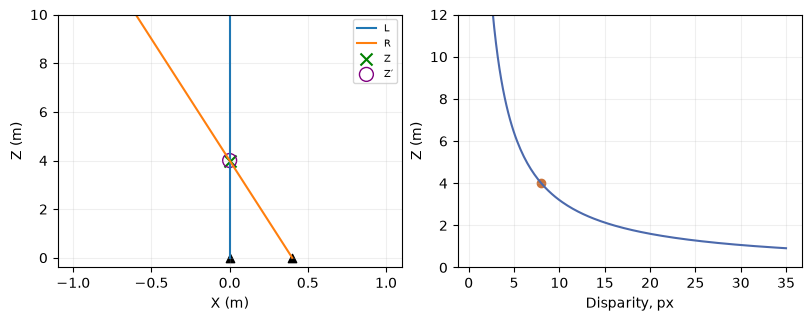

In [2]:
display(rays_figure(lang=lang)); plt.close()
controls(lambda B, du, Z: rays_figure(B, du, Z, lang),
         B=(0,1,.01,.4), du=(-4,4,.1,0), Z=(1,8,.1,4))


## 2. Eight pixels become four meters

Let $X$ be the target’s rightward offset from the left camera in meters, and $Z$ its forward distance in meters. Focal length $f$ is measured in pixels. The principal point has horizontal coordinate $c_x$. In the right camera the same target is at $X-B$. The recorded image columns are $u_L,u_R$.

$$
u_L=c_x+fX/Z,\qquad u_R=c_x+f(X-B)/Z.
$$

Subtracting the right column from the left cancels the shared $c_x$. The numerator contains $X-(X-B)=B$. The column difference $d=u_L-u_R$ is called disparity. This gives $d=fB/Z$. Multiplying by $Z$ and dividing by $d$ isolates depth, $Z=fB/d$.

Here $f=80$ pixels, $B=0.4$ m, $X=0$, $c_x=40$, and $Z=4$ m. The left column is 40 and the right is $40+80(0-0.4)/4=32$. Their difference is $40-32=8$ pixels. Depth is $80\cdot0.4/8=4$ m. The pixel units cancel. Moving the right mark one pixel to the right makes $d=7$ and puts the target at $32/7\approx4.57$ m. At $B=0$ both rays start at the same point, so one mark cannot determine depth. With nonzero baseline and $d=0$, there is no finite intersection in this setup.

Cameras on a walk around an object also rotate. Each image mark then defines a ray from its own camera center in a direction determined by that camera’s parameters. Noise can make two rays miss one another. Reconstruction looks for a 3D point whose **projections** lie near the recorded marks across several images.


In [3]:
for B, shift in [(.4,0), (.4,1), (.05,0), (.05,1)]:
    uL, uR = 40, 40-80*B/4+shift
    print(B, shift, "→", triangulate(80,B,uL,uR))
assert triangulate(80,.4,40,32) == 4


0.4 0 → 4.0
0.4 1 → 4.571428571428571
0.05 0 → 4.0
0.05 1 → None


## 3. What goes into a capture

Small camera steps keep recognizable fine details in neighboring photographs. A static matte object, diffuse light and sharp exposures make corresponding points easier to recognize. A second arc at another height opens up the top surface. Rotating the camera in place changes its direction while barely moving its center. The rays then constrain depth poorly. Very large steps lose shared details. Glass, a pedestrian, a repeated ornament or a highlight can produce convincing matches that belong to different world points.

Motion blur erases distinctive corners. Automatic exposure can turn the same wall from dark to light between frames. A small reprojection error on visible points says little about an unseen back surface. Before training we can already inspect both the images and the camera locations.


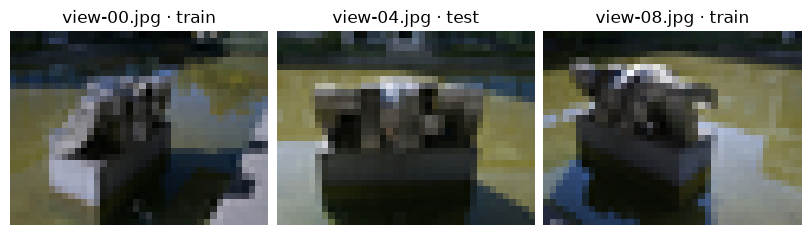

train: 8 test: 1


In [4]:
frames, seeds = photo_capture()
fig, axes = plt.subplots(1,3,figsize=(8,2.8),layout="constrained")
for ax, index in zip(axes,[0,4,8]):
    f=frames[index]
    ax.imshow(f["rgb"]); ax.set_title(f["name"]+" · "+f["split"]); ax.axis("off")
plt.show()
print("train:", sum(f["split"]=="train" for f in frames), "test:", sum(f["split"]=="test" for f in frames))


## 4. Inside a sparse reconstruction

Nine small real photographs of **struktur28_auto** from PhysicalAI-NuRec-PPISP (NVIDIA Corporation, CC BY 4.0) are included with the course. Their intrinsic and extrinsic camera parameters are known. The cloud contains points. A point can have a track listing the images and 2D observation indices where it was recognized. The middle image view-04 is reserved for image evaluation. Camera poses are provided for the complete set, so this experiment measures image synthesis at a **known pose**. The [photograph notes](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example) document the source, license and transformations.

In a COLMAP text export, **cameras.txt** identifies the lens model. PINHOLE stores width, height and $f_x,f_y,c_x,c_y$. In **images.txt**, the first row of each image gives quaternion $(w,x,y,z)$, translation $t$, camera ID and filename. The next row stores triples of pixel x, pixel y and 3D point ID. ID −1 marks an observation with no reconstructed point. **points3D.txt** associates point IDs with position, RGB, error and track. ID 93 need not be row number 93.

COLMAP stores the **world-to-camera** transform $p_c=R p_w+t$. The camera center has zero coordinates in its own frame. Substitution gives $0=R C+t$. Moving $t$ across and undoing the rotation yields $C=-R^T t$. With an identity rotation and $t=(-0.4,0,0)$, the camera stands at $(+0.4,0,0)$. This often accounts for a sign error. Our renderer stores $C$ and the **camera-to-world** rotation $R^T$.

COLMAP’s first pixel center is $(0.5,0.5)$, while the first array sample here is $(0,0)$. Resizing width 160 to 40 uses $s=40/160=0.25$. The new focal length is $f'_x=s f_x$ and the principal point becomes $c'_x=s c_x-0.5$. Starting from $c_x=80$ gives 19.5, halfway between 19 and 20. Vertical coordinates use the actual ratio of heights after rounding. Shrinking only the image without updating $f_x$ would move its predicted pixels.


In [5]:
cam = frames[0]["camera"]
R = np.array(cam["rotation"]).T  # world to camera
C = np.array(cam["center"])
t = -R @ C
assert np.allclose(-R.T @ t, C)
print("C:", C.round(3), "f:", np.round(cam["focal"],3), "c:", cam["principal"])

# A measured feature and its projection in the original (160 x 120) training view.
from reconstruction_demos import ROOT
from geometry3d import project_point, quaternion_matrix
model_dir = ROOT / "data/photographic-example/sparse/0"
rows = [line for line in (model_dir/"images.txt").read_text().splitlines() if not line.startswith("#")]
header = rows[0].split()
observation = rows[1].split()
u, v, point_id = float(observation[0]), float(observation[1]), observation[2]
point_rows = (model_dir/"points3D.txt").read_text().splitlines()
point = next(line.split() for line in point_rows if line and line.split()[0] == point_id)
X = np.array(point[1:4],float)
world_to_cam = quaternion_matrix([float(v) for v in header[1:5]])
t0 = np.array(header[5:8],float)
intrinsics = next(line.split() for line in (model_dir/"cameras.txt").read_text().splitlines()
                  if line and not line.startswith("#"))
fx, fy, cx, cy = map(float,intrinsics[4:])
observed = np.array([u-.5,v-.5])
camera_point = world_to_cam @ X + t0
pred = project_point(camera_point,[fx,fy],[cx-.5,cy-.5])
wrong = project_point(camera_point+[.08,0,0],[fx,fy],[cx-.5,cy-.5])
print("point ID", point_id, "observed:", observed.round(3), "projected:", pred.round(3))
print("reprojection error (px):",round(np.linalg.norm(pred-observed),3),
      "after translation:",round(np.linalg.norm(wrong-observed),3))


C: [-0.528  0.407 -4.51 ] f: [42.363 42.705] c: [19.5, 14.5]
point ID 26 observed: [ 30.667 113.767] projected: [ 30.989 113.992]
reprojection error (px): 0.393 after translation: 4.012


## 5. A new set of photographs

The preceding calculation uses a real observed feature in the first photograph. Its ID connects two measured image coordinates to a 3D point. A world-to-camera transform and projection predict a pixel. Adding 0.08 scene units to the camera transform’s horizontal translation deliberately moves this prediction away from the observation. The final line reports both error lengths in pixels.

For a static scene the detector first finds image features. Matching proposes pairs and geometric verification rejects inconsistent matches. The mapper registers cameras, triangulates points and refines camera and point parameters jointly against reprojection errors. An error here is the distance from the observed pixel to its predicted location. An offset of 3 pixels horizontally and 4 vertically has length √(9+16) = 5 pixels.

The commands below use an installed COLMAP. The raw photos are in capture/input; the empty capture/sparse and capture/text directories already exist. `exhaustive_matcher` considers all image pairs, which suits a small collection. If mapping produces several disconnected components, the example’s directory 0 stands for the connected model containing the relevant views.

```sh
colmap feature_extractor --database_path capture/database.db --image_path capture/input
colmap exhaustive_matcher --database_path capture/database.db
colmap mapper --database_path capture/database.db --image_path capture/input --output_path capture/sparse
colmap image_undistorter --image_path capture/input --input_path capture/sparse/0 --output_path capture/undistorted --output_type COLMAP
colmap model_converter --input_path capture/undistorted/sparse --output_path capture/text --output_type TXT
```

The course loader now reads `capture/text` and `capture/undistorted/images`. The undistorted model matters because our camera implements perspective division alone. A distorted photograph and an ideal pinhole camera disagree most near the edges. A large capture can be downsampled for a small experiment. The loader handles image resampling and camera scaling together.

[COLMAP commands](https://colmap.github.io/cli.html) · [Model format](https://colmap.github.io/format.html) · [Capture and reconstruction](https://colmap.github.io/tutorial.html)

## An experiment

Two reconstructions have the same mean reprojection error. In one the cameras barely move; in the other they follow an arc around the subject. Do they determine depth equally well?

<details><summary>Worked answer</summary>

In the first capture, moving a point along the viewing ray hardly changes its image. A small image error can coexist with large depth uncertainty. The second capture intersects rays from different directions and constrains the position more tightly. Track lengths, camera layout and the photographs help explain the difference.

</details>
